# Ácidos orgânicos do cotidiano: cítrico, lático e ascórbico
### Funções inorgânicas — ácidos

**Objetivo:** Reconhecer o grupo carboxila, comparar os poliácidos do limão e do iogurte e calcular o teor de ácido de uma amostra por titulação.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Os ácidos que aparecem na cozinha são, quase todos, **ácidos carboxílicos** — moléculas orgânicas com o grupo funcional

$$
\boxed{\mathrm{-COOH}\ \text{(carboxila)} = \mathrm{C(=O)OH}}
$$

O hidrogênio ligado ao oxigênio é o único que se ioniza; os hidrogênios ligados ao carbono não saem. Por isso a força do ácido depende de quantos grupos $-COOH$ a molécula tem e de como o resto da cadeia estabiliza o ânion.

| Ácido | Fórmula | Grupos $-COOH$ | Onde aparece |
|---|---|---|---|
| cítrico | $\mathrm{C_6H_8O_7}$ | 3 | limão, laranja, refrigerante |
| lático | $\mathrm{C_3H_6O_3}$ | 1 | iogurte, leite fermentado, músculo |
| ascórbico (vitamina C) | $\mathrm{C_6H_8O_6}$ | 1 | frutas cítricas, acerola |
| acético | $\mathrm{C_2H_4O_2}$ | 1 | vinagre |

Para medir **quanto** ácido existe numa amostra, o método é a titulação ácido-base:

$$
\boxed{n_{\text{ácido}} = \frac{n_{\mathrm{NaOH}}}{k}}, \qquad
m_{\text{ácido}} = n_{\text{ácido}} \cdot M
$$

em que $k$ é o número de hidrogênios ácidos por molécula (1 no lático e no acético, 3 no cítrico).

## 2. Exemplo resolvido passo a passo

**Situação:** titular $10{,}0\ \mathrm{mL}$ de suco de limão com $\mathrm{NaOH}$ a $0{,}100\ \mathrm{mol/L}$; gastaram-se $8{,}0\ \mathrm{mL}$ de base. Considerando o ácido cítrico ($M = 192{,}12\ \mathrm{g/mol}$) como único ácido:

**Passo 1 — mols de base.**

$$
n_{\mathrm{NaOH}} = c\cdot V = 0{,}100 \cdot 0{,}0080 = 8{,}0\times10^{-4}\ \mathrm{mol}
$$

**Passo 2 — mols de ácido (3 prótons).**

$$
n_{\text{cítrico}} = \frac{8{,}0\times10^{-4}}{3} = 2{,}67\times10^{-4}\ \mathrm{mol}
$$

**Passo 3 — massa e concentração comum.**

$$
m = n\cdot M = 2{,}67\times10^{-4}\cdot 192{,}12 = \boxed{0{,}0512\ \mathrm{g}}
$$

$$
\text{teor} = \frac{0{,}0512\ \mathrm{g}}{10{,}0\ \mathrm{mL}} = 5{,}1\ \mathrm{g/L} \approx 0{,}51\ \mathrm{g/100\ mL}
$$

O valor é compatível com o de um limão comum (0,4 a 0,6 g/100 mL de ácido cítrico).

## 3. Conferindo o cálculo com Python

In [2]:
# @title Titulação do suco de limão
from rdkit import Chem
from rdkit.Chem import Descriptors

SMILES_CITRICO = "OC(=O)CC(O)(CC(=O)O)C(=O)O"     # ácido cítrico
M_CITRICO = Descriptors.MolWt(Chem.MolFromSmiles(SMILES_CITRICO))

C_NAOH = 0.100        # mol/L
V_NAOH = 8.0e-3       # L
V_AMOSTRA = 10.0e-3   # L (10 mL de suco)
PROTONS = 3           # grupos -COOH do cítrico

n_base = C_NAOH * V_NAOH
n_acido = n_base / PROTONS
massa = n_acido * M_CITRICO
teor_g_100mL = 100 * massa / (V_AMOSTRA * 1000)

print(f"Massa molar do ácido cítrico: {M_CITRICO:.2f} g/mol")
print(f"n(NaOH) = {n_base:.2e} mol")
print(f"n(ácido) = {n_acido:.2e} mol")
print(f"massa de ácido na alíquota: {massa * 1000:.1f} mg")
print(f"teor: {teor_g_100mL:.2f} g/100 mL")
print(f"equivalente-grama (M/3): {M_CITRICO / 3:.2f} g/eq")

Massa molar do ácido cítrico: 192.12 g/mol
n(NaOH) = 8.00e-04 mol
n(ácido) = 2.67e-04 mol
massa de ácido na alíquota: 51.2 mg
teor: 0.51 g/100 mL
equivalente-grama (M/3): 64.04 g/eq


## 4. Visualização

### 4.1 Ácido cítrico em 3D — arraste para girar

Três carboxilas em volta de uma cadeia curta: cada uma pode perder um próton, mas com $K_a$ diferentes ($3{,}1\times10^{-4}$, $1{,}7\times10^{-5}$ e $4{,}0\times10^{-7}$). Gire a figura e conte os grupos $\mathrm{-COOH}$.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("OC(=O)CC(O)(CC(=O)O)C(=O)O", altura=460)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Ácido lático e ácido ascórbico em 3D

O lático é o que dá o gosto azedo ao iogurte (produzido pelas bactérias do leite). O ascórbico é a vitamina C: também é um ácido, e é o que faz o suco de laranja escurecer menos quando está fresco.

In [4]:
molecula_3d("CC(O)C(=O)O")          # ácido lático

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [5]:
molecula_3d("OC[C@H](O)[C@H]1OC(=O)C(O)=C1O")   # ácido ascórbico (vitamina C)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os quatro em 2D, com os risquinhos

Repare no **risco duplo** do $\mathrm{C=O}$ e no $-OH$ da carboxila. É esse $-OH$ (não o $-OH$ do álcool, no caso do lático e do ascórbico) que libera o próton.

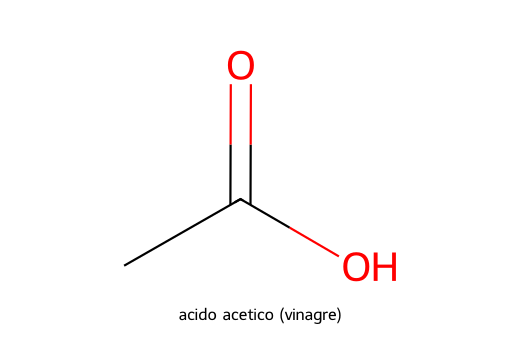

In [6]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("OC(=O)CC(O)(CC(=O)O)C(=O)O", legenda="acido citrico (3 COOH)")
estrutura_2d("CC(O)C(=O)O", legenda="acido latico (1 COOH)")
estrutura_2d("OC[C@H](O)[C@H]1OC(=O)C(O)=C1O", legenda="acido ascorbico (vitamina C)")
estrutura_2d("CC(=O)O", legenda="acido acetico (vinagre)")

### 4.4 Realçando o grupo carboxila

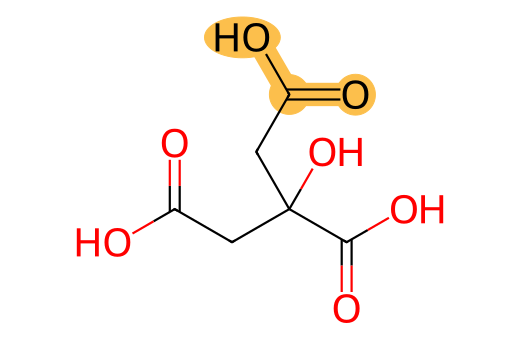

In [7]:
# @title Grupo funcional em destaque
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

def estrutura_realcada(smiles, smarts="C(=O)[OH]", largura=520, altura=340):
    mol = Chem.MolFromSmiles(smiles)
    padrao = Chem.MolFromSmarts(smarts)
    correspondencia = mol.GetSubstructMatch(padrao)
    rdDepictor.Compute2DCoords(mol)
    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.DrawMolecule(mol, highlightAtoms=list(correspondencia),
                         highlightAtomColors={i: (0.99, 0.75, 0.30) for i in correspondencia})
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_realcada("OC(=O)CC(O)(CC(=O)O)C(=O)O")   # as três carboxilas ficam laranja

### 4.5 pH das bebidas e alimentos

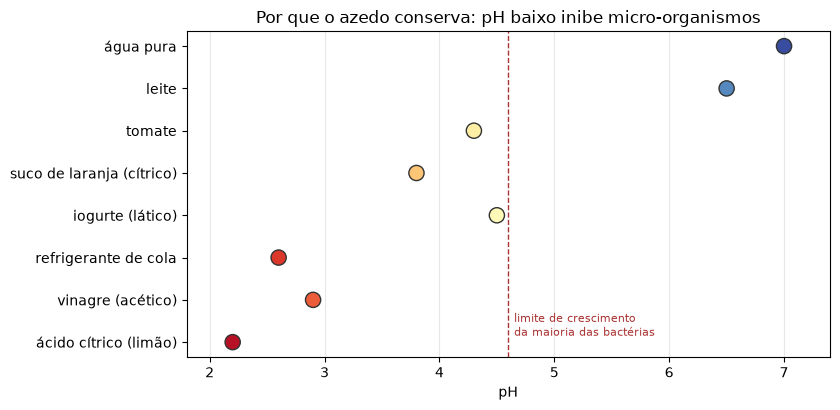

In [8]:
# @title pH de alimentos comuns
import matplotlib.pyplot as plt

alimentos = [
    ("ácido cítrico (limão)", 2.2), ("vinagre (acético)", 2.9),
    ("refrigerante de cola", 2.6), ("iogurte (lático)", 4.5),
    ("suco de laranja (cítrico)", 3.8), ("tomate", 4.3),
    ("leite", 6.5), ("água pura", 7.0),
]
nomes = [nome for nome, _ in alimentos]
valores = [valor for _, valor in alimentos]

plt.figure(figsize=(8.5, 4.2))
cores = plt.cm.RdYlBu([(v - 2) / 5.2 for v in valores])
plt.scatter(valores, range(len(valores)), s=120, c=cores, edgecolor="#333", zorder=3)
plt.yticks(range(len(valores)), nomes)
plt.axvline(4.6, color="#a33", linestyle="--", linewidth=1)
plt.text(4.65, 0.15, "limite de crescimento\nda maioria das bactérias", fontsize=8, color="#a33")
plt.xlim(1.8, 7.4)
plt.xlabel("pH")
plt.title("Por que o azedo conserva: pH baixo inibe micro-organismos")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Teor de vitamina C em frutas

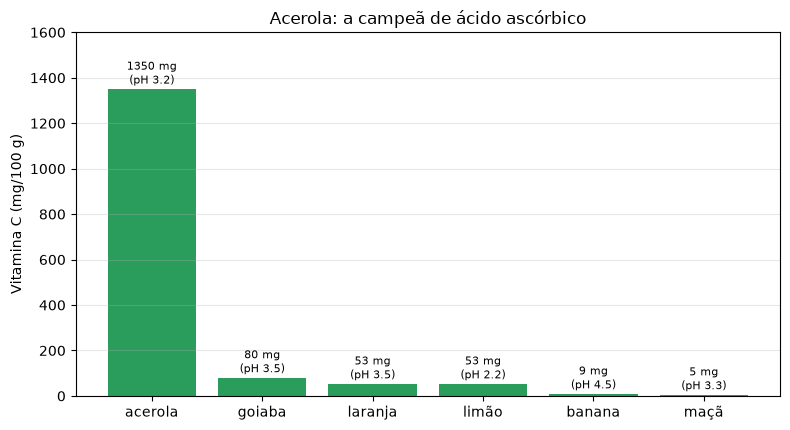

In [9]:
# @title Vitamina C por 100 g de fruta
frutas = ["acerola", "goiaba", "laranja", "limão", "banana", "maçã"]
mg_por_100g = [1350, 80, 53, 53, 9, 5]
acidez = [3.2, 3.5, 3.5, 2.2, 4.5, 3.3]     # pH aproximado

plt.figure(figsize=(8, 4.4))
barras = plt.bar(frutas, mg_por_100g, color="#2a9d5c")
for barra, valor, ph_ in zip(barras, mg_por_100g, acidez):
    plt.annotate(f"{valor} mg\n(pH {ph_})", (barra.get_x() + barra.get_width() / 2, valor),
                 xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
plt.ylim(0, 1600)
plt.ylabel("Vitamina C (mg/100 g)")
plt.title("Acerola: a campeã de ácido ascórbico")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- O teor calculado ($0{,}51\ \mathrm{g/100\ mL}$) só vale se **todo** o ácido for cítrico; o suco tem também málico e ascórbico. Por isso a titulação mede a *acidez total*, expressa "em ácido cítrico".
- Esquecer de dividir por 3 infla o resultado em três vezes — é o erro mais comum na titulação de um poliácido.
- No 2D, o destaque laranja mostra exatamente quais átomos formam o grupo ácido: o carbono, o oxigênio da carbonila e o oxigênio da hidroxila.
- Ácido fraco também: mesmo o cítrico, com três $-COOH$, tem pH em torno de 2 — não é um pH de ácido forte porque só uma parte das moléculas ioniza.

## 6. Exercício de fixação

$5{,}0\ \mathrm{mL}$ de vinagre foram titulados e consumiram $33{,}3\ \mathrm{mL}$ de $\mathrm{NaOH}$ $0{,}100\ \mathrm{mol/L}$. Qual o teor de ácido acético em $\mathrm{g/100\ mL}$? (Compare com o vinagre de cozinha, que tem cerca de 4 g/100 mL.)

In [10]:
# @title Exercício
M_ACETICO = Descriptors.MolWt(Chem.MolFromSmiles("CC(=O)O"))
V_BASE = 33.3e-3
V_VINAGRE = 5.0e-3

n_ac = C_NAOH * V_BASE          # 1 próton: n(ácido) = n(base)
m_ac = n_ac * M_ACETICO
teor = 100 * m_ac / (V_VINAGRE * 1000)
print(f"M(acético) = {M_ACETICO:.2f} g/mol")
print(f"n(ácido)   = {n_ac:.2e} mol")
print(f"massa      = {m_ac * 1000:.1f} mg")
print(f"teor       = {teor:.2f} g/100 mL")

M(acético) = 60.05 g/mol
n(ácido)   = 3.33e-03 mol
massa      = 200.0 mg
teor       = 4.00 g/100 mL


## 7. Resumo

- Ácidos do cotidiano são carboxílicos: só o H do $-COOH$ sai.
- Cítrico tem 3 grupos ácidos; lático, ascórbico e acético têm 1.
- Titulação: $n_{\text{ácido}} = n_{\text{base}}/k$ e $m = nM$.
- Teor em $\mathrm{g/100\ mL}$ = massa na alíquota dividida pelo volume, em escala.
- pH baixo conserva alimentos porque inibe bactérias e fungos.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- Tabela Brasileira de Composição de Alimentos (TACO).
- IUPAC. *Compendium of Chemical Terminology* (Gold Book).